# 01 · Calidad y limpieza de datos

**Fase: Find the truth.** Este notebook carga los archivos crudos de `dataset_start/`, revisa cada tabla, detecta los errores sembrados en los datos, los corrige y guarda las tablas limpias en `data_clean/`.

Contenido:
1. Carga de los archivos crudos
2. Perfil rápido de cada tabla
3. Detección de problemas, tabla por tabla
4. Limpieza
5. Validaciones después de limpiar
6. Resumen de problemas y exportación

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

RAW = Path('../dataset_start')
CLEAN = Path('../data_clean')
CLEAN.mkdir(exist_ok=True)

VALID_ASSETS = [f'VF_A0{i}' for i in range(1, 9)]

## 1. Carga de los archivos crudos
Todo se lee como texto o con el tipo que pandas infiere; no se corrige nada todavía. Algunos archivos traen BOM, por eso `utf-8-sig`.

In [2]:
read = lambda f: pd.read_csv(RAW / f, encoding='utf-8-sig')

prices_raw = read('01_market_prices_raw.csv')
expanded_raw = read('01_market_prices_raw_expanded.csv')
macro_raw = read('02_macro_raw.csv')
fund_raw = read('03_fundamentals_raw.csv')
ref = read('04_asset_reference.csv')
clients = read('05_client_profiles.csv')
events = read('06_events.csv')

tables = {
    '01_market_prices_raw': prices_raw,
    '01_market_prices_raw_expanded': expanded_raw,
    '02_macro_raw': macro_raw,
    '03_fundamentals_raw': fund_raw,
    '04_asset_reference': ref,
    '05_client_profiles': clients,
    '06_events': events,
}
pd.DataFrame({n: {'filas': len(t), 'columnas': t.shape[1]} for n, t in tables.items()}).T

,filas,columnas
01_market_prices_raw,2175,9
01_market_prices_raw_expanded,538836,9
02_macro_raw,271,9
03_fundamentals_raw,65,7
04_asset_reference,8,7
05_client_profiles,3,9
06_events,5,5


## 2. Perfil rápido de cada tabla
Tipos, nulos y duplicados exactos. Una columna numérica que aparece como `object`/`str` es la primera pista de un problema.

In [3]:
def profile(df):
    return pd.DataFrame({
        'tipo': df.dtypes.astype(str),
        'nulos': df.isna().sum(),
        'únicos': df.nunique(),
        'ejemplo': df.iloc[0],
    })

for name, t in tables.items():
    print(f'\n=== {name}  {t.shape}  duplicados exactos: {t.duplicated().sum()}')
    display(profile(t))


=== 01_market_prices_raw  (2175, 9)  duplicados exactos: 7


,tipo,nulos,únicos,ejemplo
date,str,0,273,2025-08-01
asset_id,str,0,11,VF_A01
market,str,0,3,NYSE ADR
currency,str,4,1,USD
open,float64,0,1797,52.09
high,float64,0,1811,52.21
low,float64,0,1810,51.6
close,float64,0,1808,51.97
volume,str,3,2165,1833095



=== 01_market_prices_raw_expanded  (538836, 9)  duplicados exactos: 12


,tipo,nulos,únicos,ejemplo
date,str,0,67391,2020-01-02 09:30:00
asset_id,str,0,11,VF_A01
market,str,0,3,NYSE ADR
currency,str,35,1,USD
open,float64,0,15407,79.75
high,float64,0,15421,79.83
low,float64,0,15339,79.28
close,float64,24,15402,79.36
volume,str,30,131118,96246



=== 02_macro_raw  (271, 9)  duplicados exactos: 0


,tipo,nulos,únicos,ejemplo
date,str,0,271,2025-08-01
us_10y_yield,float64,0,155,4.353
us_inflation_yoy,float64,258,9,3.0
usd_cop,float64,0,269,4090.92
usd_pen,float64,0,238,3.7233
usd_mxn,float64,0,264,18.713
usd_clp,float64,0,266,936.21
market_factor,float64,0,271,-0.009135
risk_regime,str,0,3,Normal


... (4 outputs left out)


=== 05_client_profiles  (3, 9)  duplicados exactos: 0


,tipo,nulos,únicos,ejemplo
client_id,str,0,3,CL_01
profile_name,str,0,3,Crecimiento Global
base_currency,str,0,3,USD
horizon_months,int64,0,3,18
risk_tolerance,str,0,3,Alta
max_drawdown_tolerance_pct,int64,0,3,22
liquidity_need,str,0,2,Baja
priority,str,0,3,Crecimiento de capital
constraint,str,0,3,Máx. 45% en un solo sector



=== 06_events  (5, 5)  duplicados exactos: 0


,tipo,nulos,únicos,ejemplo
event_date,str,0,5,2026-02-10
scope,str,0,5,VF_A02
event_type,str,0,5,Operational
headline,str,0,5,Interrupción temporal de un proveedor crítico ...
severity,str,0,2,High


Tablas de referencia (pequeñas, se ven completas):

In [4]:
display(ref); display(clients); display(events)

,asset_id,issuer_id,name,sector,country,market,currency
0,VF_A01,ISS_01,Andes Consumer,Consumer Staples,Colombia,NYSE ADR,USD
1,VF_A02,ISS_02,Pacifica Digital,Technology,Peru,NASDAQ,USD
2,VF_A03,ISS_03,Cordillera Energy,Energy,Colombia,NYSE ADR,USD
3,VF_A04,ISS_04,Lima Financial,Financials,Peru,NYSE ADR,USD
4,VF_A05,ISS_05,Aurora Health,Health Care,United States,NYSE,USD
5,VF_A06,ISS_06,Norte Industrials,Industrials,Mexico,NYSE ADR,USD
6,VF_A07,ISS_07,Sierra Materials,Materials,Chile,NYSE ADR,USD
7,VF_A08,ISS_08,Atlas Utilities,Utilities,United States,NYSE,USD


,client_id,profile_name,base_currency,horizon_months,risk_tolerance,max_drawdown_tolerance_pct,liquidity_need,priority,constraint
0,CL_01,Crecimiento Global,USD,18,Alta,22,Baja,Crecimiento de capital,Máx. 45% en un solo sector
1,CL_02,Patrimonio Estable,COP,36,Media-Baja,10,Media,Preservación + crecimiento moderado,Máx. 25% en activos de alta volatilidad
2,CL_03,Diversificación Regional,PEN,24,Media,15,Media,Diversificación geográfica,Al menos 3 países y 3 sectores


,event_date,scope,event_type,headline,severity
0,2026-02-10,VF_A02,Operational,Interrupción temporal de un proveedor crítico ...,High
1,2026-04-06,VF_A03,Commodity,Mejora abrupta en margen de referencia energético,Medium
2,2026-05-18,VF_A04,Earnings,Resultados superan expectativas internas del m...,Medium
3,2026-06-08,VF_A07,Demand,Debilidad inesperada en demanda externa del se...,High
4,2026-07-21,Technology,Sector,Repricing de múltiplos en compañías de crecimi...,Medium


## 3. Detección de problemas

### 3.1 Precios diarios (`01_market_prices_raw`)
Se revisa: IDs de activo, formato de fecha, duplicados por (fecha, activo), volumen no numérico, nulos y consistencia OHLC (el cierre debe estar entre el mínimo y el máximo).

In [5]:
issues = []  # (tabla, problema, filas, corrección)

p = prices_raw
bad_id = p[~p.asset_id.isin(VALID_ASSETS)]
print('IDs inválidos:'); display(bad_id[['date', 'asset_id', 'close']])
issues.append(('01_market_prices_raw', 'asset_id mal escrito', len(bad_id), 'Mapear al ID oficial'))

non_iso = p[~p.date.str.match(r'^\d{4}-\d{2}-\d{2}$')]
print('Fechas no ISO:'); display(non_iso[['date', 'asset_id']])
issues.append(('01_market_prices_raw', 'Fecha en formato MM/DD/YYYY', len(non_iso), 'Parsear con formato mixto'))

dups = p[p.duplicated(['date', 'asset_id'], keep='first')]
print('Duplicados (fecha, activo):', len(dups))
issues.append(('01_market_prices_raw', 'Filas duplicadas', len(dups), 'Eliminar duplicados'))

vol_num = pd.to_numeric(p.volume, errors='coerce')
vol_txt = p[vol_num.isna() & p.volume.notna()]
print('Volumen no numérico:', vol_txt.volume.tolist())
issues.append(('01_market_prices_raw', 'Volumen como texto con K', len(vol_txt), 'Convertir a número x1000'))
issues.append(('01_market_prices_raw', 'currency vacía', p.currency.isna().sum(), 'Rellenar con USD'))
issues.append(('01_market_prices_raw', 'volume vacío', p.volume.isna().sum(), 'Dejar nulo'))

ohlc_bad = p[(p.close > p.high) | (p.close < p.low)]
print('Cierre fuera del rango [low, high]:'); display(ohlc_bad)
issues.append(('01_market_prices_raw', 'Cierre x100 (error de punto decimal)', len(ohlc_bad), 'Dividir entre 100'))

IDs inválidos:


,date,asset_id,close
56,2025-08-12,VF-A1,53.74
901,2026-01-06,VF_A6,37.64
1450,2026-04-13,VFA03,28.57


Fechas no ISO:


,date,asset_id
201,09/05/2025,VF_A02
202,09/05/2025,VF_A03
203,09/05/2025,VF_A04
1202,02/27/2026,VF_A03


Duplicados (fecha, activo): 7
Volumen no numérico: ['3635.6K', '1926.5K', '1181.9K']
Cierre fuera del rango [low, high]:


,date,asset_id,market,currency,open,high,low,close,volume
1333,2026-03-23,VF_A06,NYSE ADR,USD,34.61,35.92,34.56,3589.0,726465


Qué valores toman `market` y `currency`, y si cada activo tiene siempre el mismo mercado:

In [6]:
print(p.market.value_counts(dropna=False).to_dict())
print(p.currency.value_counts(dropna=False).to_dict())
p.groupby('asset_id').market.unique()

{'NYSE ADR': 1359, 'NYSE': 544, 'NASDAQ': 272}
{'USD': 2171, nan: 4}


asset_id
VF-A1     [NYSE ADR]
VFA03     [NYSE ADR]
VF_A01    [NYSE ADR]
VF_A02      [NASDAQ]
VF_A03    [NYSE ADR]
VF_A04    [NYSE ADR]
VF_A05        [NYSE]
VF_A06    [NYSE ADR]
VF_A07    [NYSE ADR]
VF_A08        [NYSE]
VF_A6     [NYSE ADR]
Name: market, dtype: object

### 3.2 Precios intradía (`01_market_prices_raw_expanded`)
Barras de 10 minutos desde 2020. Se buscan los mismos tipos de error.

In [7]:
e = expanded_raw
checks = {
    'asset_id mal escrito': (~e.asset_id.isin(VALID_ASSETS)).sum(),
    'Fecha en formato MM/DD/YYYY HH:MM': (~e.date.str.match(r'^\d{4}-\d{2}-\d{2} ')).sum(),
    'Filas duplicadas': e.duplicated(['date', 'asset_id']).sum(),
    'close vacío': e.close.isna().sum(),
    'currency vacía': e.currency.isna().sum(),
    'volume vacío o con K': (e.volume.isna() | pd.to_numeric(e.volume, errors='coerce').isna()).sum(),
}
print('IDs encontrados:', e.asset_id.value_counts().to_dict())
fixes = ['Mapear al ID oficial', 'Parsear con formato mixto', 'Eliminar duplicados',
         'Eliminar la barra', 'Rellenar con USD', 'Convertir o dejar nulo']
for (k, v), fx in zip(checks.items(), fixes):
    issues.append(('01_market_prices_raw_expanded', k, int(v), fx))
pd.Series(checks, name='filas')

IDs encontrados: {'VF_A08': 67355, 'VF_A02': 67354, 'VF_A04': 67354, 'VF_A07': 67354, 'VF_A03': 67353, 'VF_A05': 67353, 'VF_A01': 67351, 'VF_A06': 67346, 'VF-A6': 11, 'VF-A4': 3, 'VF-A1': 2}


asset_id mal escrito                 16
Fecha en formato MM/DD/YYYY HH:MM    38
Filas duplicadas                     12
close vacío                          24
currency vacía                       35
volume vacío o con K                 75
Name: filas, dtype: int64

### 3.3 Macro (`02_macro_raw`)
La inflación US es un dato mensual: solo trae valor el día que se publica.

In [8]:
m = macro_raw
print('Nulos:', m.isna().sum()[m.isna().sum() > 0].to_dict())
print('Regímenes:', m.risk_regime.value_counts().to_dict())
print('Saltos entre fechas (días):', pd.to_datetime(m.date).diff().dt.days.value_counts().to_dict())
display(m.dropna(subset=['us_inflation_yoy'])[['date', 'us_inflation_yoy']].head())
issues.append(('02_macro_raw', 'Inflación solo mensual', int(m.us_inflation_yoy.isna().sum()), 'Rellenar hacia adelante'))

Nulos: {'us_inflation_yoy': 258}
Regímenes: {'Normal': 251, 'Stress': 10, 'Recovery': 10}
Saltos entre fechas (días): {1.0: 216, 3.0: 54}


,date,us_inflation_yoy
0,2025-08-01,3.00
21,2025-09-01,2.97
43,2025-10-01,2.96
66,2025-11-03,2.97
86,2025-12-01,2.97


### 3.4 Fundamentales (`03_fundamentals_raw`)

In [9]:
f = fund_raw
print('issuer_id:', f.issuer_id.unique().tolist())
print('period_end:', f.period_end.unique().tolist())
rev_bad = f[pd.to_numeric(f.revenue_usd_m, errors='coerce').isna()]
print('Ingresos no numéricos:'); display(rev_bad)
print('Duplicados exactos:'); display(f[f.duplicated(keep=False)])
print('Caja vacía:'); display(f[f.cash_usd_m.isna()])

issuer_id: ['ISS_01', 'ISS_02', 'ISS_03', 'ISS_04', 'ISS04', 'ISS_05', 'ISS_06', 'ISS_07', 'ISS_08']
period_end: ['2024-09-30', '2024-12-31', '2025-03-31', '2025-06-30', '2025-09-30', '2025-12-31', '2026-03-31', '2026-06-30', 'Q4-2024']
Ingresos no numéricos:


,issuer_id,period_end,revenue_usd_m,ebitda_usd_m,net_income_usd_m,debt_usd_m,cash_usd_m
43,ISS_06,2025-06-30,"1,845.7",437.4,276.0,1812.6,618.5


Duplicados exactos:


,issuer_id,period_end,revenue_usd_m,ebitda_usd_m,net_income_usd_m,debt_usd_m,cash_usd_m
19,ISS_03,2025-06-30,3245.2,446.7,257.0,448.2,469.2
64,ISS_03,2025-06-30,3245.2,446.7,257.0,448.2,469.2


Caja vacía:


,issuer_id,period_end,revenue_usd_m,ebitda_usd_m,net_income_usd_m,debt_usd_m,cash_usd_m
52,ISS_07,2025-09-30,5111.6,1033.9,611.5,920.8,NaN


La fila `Q4-2024` de ISS_02 está donde iría junio 2025, y ISS_02 ya tiene un 2024-12-31. Además, el ingreso de ISS_06 en junio 2025 (`"1,845.7"`) cae −35% y luego sube +55%: parece un error de dígito (2,845.7).

In [10]:
display(f[f.issuer_id == 'ISS_02'])
display(f[f.issuer_id == 'ISS_06'][['issuer_id', 'period_end', 'revenue_usd_m', 'ebitda_usd_m']])

issues += [
    ('03_fundamentals_raw', 'issuer_id mal escrito (ISS04)', int((f.issuer_id == 'ISS04').sum()), 'Mapear a ISS_04'),
    ('03_fundamentals_raw', 'Ingreso como texto con coma', len(rev_bad), 'Quitar la coma; supuesto 2,845.7'),
    ('03_fundamentals_raw', 'period_end = Q4-2024 (ISS_02)', int((f.period_end == 'Q4-2024').sum()), 'Supuesto: reasignar a 2025-06-30'),
    ('03_fundamentals_raw', 'Fila duplicada exacta', int(f.duplicated().sum()), 'Eliminar duplicado'),
    ('03_fundamentals_raw', 'cash_usd_m vacío', int(f.cash_usd_m.isna().sum()), 'Interpolar entre trimestres'),
]

,issuer_id,period_end,revenue_usd_m,ebitda_usd_m,net_income_usd_m,debt_usd_m,cash_usd_m
8,ISS_02,2024-09-30,2778.1,784.7,407.9,1710.9,945.4
9,ISS_02,2024-12-31,2830.8,755.8,350.1,1691.8,928.0
10,ISS_02,2025-03-31,2973.8,850.3,540.9,1690.2,924.2
11,ISS_02,Q4-2024,2928.4,830.4,374.7,1678.8,903.9
12,ISS_02,2025-09-30,2915.4,857.4,406.2,1690.2,915.2
13,ISS_02,2025-12-31,3126.4,882.5,500.8,1701.1,895.8
14,ISS_02,2026-03-31,3119.3,861.1,542.3,1684.7,879.8
15,ISS_02,2026-06-30,3221.6,876.2,444.3,1712.8,906.3


,issuer_id,period_end,revenue_usd_m,ebitda_usd_m
40,ISS_06,2024-09-30,2742.3,413.9
41,ISS_06,2024-12-31,2747.0,380.8
42,ISS_06,2025-03-31,2841.6,477.7
43,ISS_06,2025-06-30,"1,845.7",437.4
44,ISS_06,2025-09-30,2861.2,439.6
45,ISS_06,2025-12-31,3001.8,501.5
46,ISS_06,2026-03-31,3030.6,395.4
47,ISS_06,2026-06-30,3106.5,497.5


## 4. Limpieza
Cada función corrige solo los problemas encontrados arriba, para que quede trazable.

In [11]:
ID_MAP = {'VF-A1': 'VF_A01', 'VF_A6': 'VF_A06', 'VFA03': 'VF_A03', 'VF-A4': 'VF_A04', 'VF-A6': 'VF_A06'}

def parse_volume(s):
    s = s.astype('string')
    k = s.str.endswith('K').fillna(False)
    v = pd.to_numeric(s.str.replace('K', '', regex=False), errors='coerce')
    return np.where(k, v * 1000, v)

def clean_prices(df):
    df = df.copy()
    df['asset_id'] = df.asset_id.replace(ID_MAP)
    df['date'] = pd.to_datetime(df.date, format='mixed')
    df['volume'] = parse_volume(df.volume)
    df['currency'] = df.currency.fillna('USD')
    df = df.dropna(subset=['close']).drop_duplicates(['date', 'asset_id'])
    x100 = df.close > df.high * 1.05
    df.loc[x100, 'close'] = df.loc[x100, 'close'] / 100
    return df.sort_values(['asset_id', 'date']).reset_index(drop=True)

prices = clean_prices(prices_raw)
expanded = clean_prices(expanded_raw)

macro = macro_raw.copy()
macro['date'] = pd.to_datetime(macro.date)
macro['us_inflation_yoy'] = macro.us_inflation_yoy.ffill()

fund = fund_raw.copy()
fund['issuer_id'] = fund.issuer_id.replace({'ISS04': 'ISS_04'})
fund.loc[(fund.issuer_id == 'ISS_02') & (fund.period_end == 'Q4-2024'), 'period_end'] = '2025-06-30'
fund.loc[(fund.issuer_id == 'ISS_06') & (fund.period_end == '2025-06-30'), 'revenue_usd_m'] = '2845.7'
fund['revenue_usd_m'] = pd.to_numeric(fund.revenue_usd_m.astype(str).str.replace(',', ''))
fund['period_end'] = pd.to_datetime(fund.period_end)
fund = fund.drop_duplicates().sort_values(['issuer_id', 'period_end']).reset_index(drop=True)
fund['cash_usd_m'] = fund.groupby('issuer_id').cash_usd_m.transform(lambda s: s.interpolate())

events_c = events.copy()
events_c['event_date'] = pd.to_datetime(events_c.event_date)

## 5. Validaciones después de limpiar
Si alguna falla, la celda lanza un error.

In [12]:
assert set(prices.asset_id) == set(VALID_ASSETS)
assert set(expanded.asset_id) == set(VALID_ASSETS)
assert not prices.duplicated(['date', 'asset_id']).any()
assert not expanded.duplicated(['date', 'asset_id']).any()
assert ((prices.close <= prices.high) & (prices.close >= prices.low)).all()
assert prices.groupby('asset_id').size().nunique() == 1, 'todos los activos deben tener los mismos días'
assert set(prices.date) <= set(macro.date), 'todas las fechas de precios deben existir en macro'
assert fund.groupby('issuer_id').size().eq(8).all(), '8 trimestres por emisor'
assert not fund.duplicated(['issuer_id', 'period_end']).any()
assert fund.cash_usd_m.notna().all()
assert set(ref.issuer_id) == set(fund.issuer_id)
print('Todas las validaciones pasaron')
print('Días por activo (diario):', prices.groupby('asset_id').size().iloc[0])
print('Rango diario:', prices.date.min().date(), '→', prices.date.max().date())
print('Rango expanded:', expanded.date.min(), '→', expanded.date.max())

Todas las validaciones pasaron
Días por activo (diario): 271
Rango diario: 2025-08-01 → 2026-08-14
Rango expanded: 2020-01-02 09:30:00 → 2026-08-14 15:50:00


### 5.1 ¿Coinciden las dos fuentes de precios?
Si el archivo diario saliera del expanded, al agrupar las barras de 10 minutos por día deberían salir los mismos valores:
open = primera barra, high = máximo, low = mínimo, close = última barra, volumen = suma de las barras.

Primero se revisa que cada archivo sea coherente por dentro.

In [13]:
e = expanded.copy()
e['day'] = e.date.dt.normalize()
e['prev_close'] = e.groupby('asset_id').close.shift()
same_day = e.day.eq(e.groupby('asset_id').day.shift())

internal = pd.Series({
    'expanded: barras con open/close fuera de [low, high]':
        int(((e.open > e.high) | (e.open < e.low) | (e.close > e.high) | (e.close < e.low)).sum()),
    'expanded: % de barras que abren en el cierre de la anterior (mismo día)':
        round(((e.open - e.prev_close).abs() < 0.011)[same_day].mean() * 100, 1),
    'diario: filas con open/close fuera de [low, high]':
        int(((prices.open > prices.high) | (prices.open < prices.low) | (prices.close > prices.high) | (prices.close < prices.low)).sum()),
}, name='valor')
internal.to_frame()

,valor
"expanded: barras con open/close fuera de [low, high]",0.0
expanded: % de barras que abren en el cierre de la anterior (mismo día),100.0
"diario: filas con open/close fuera de [low, high]",0.0


Los dos archivos son coherentes por dentro. Ahora se comparan entre sí, columna por columna, en las fechas que comparten.

In [14]:
exp_ohlc = (e.groupby(['asset_id', 'day'])
              .agg(open=('open', 'first'), high=('high', 'max'), low=('low', 'min'),
                   close=('close', 'last'), volume=('volume', 'sum'), bars=('close', 'size'))
              .reset_index().rename(columns={'day': 'date'}))

cmp = prices[['date', 'asset_id', 'open', 'high', 'low', 'close', 'volume']].merge(
    exp_ohlc, on=['date', 'asset_id'], suffixes=('_d', '_e'))
print('Días en común:', len(cmp))

rows = {}
for c in ['open', 'high', 'low', 'close']:
    dif = (cmp[c + '_d'] / cmp[c + '_e'] - 1) * 100
    cmp['dif_' + c] = dif
    rows[c] = {'coinciden_%': (dif.abs() < 0.1).mean() * 100, 'dif_media_abs_%': dif.abs().mean(), 'dif_máx_abs_%': dif.abs().max()}
vr = cmp.volume_d / cmp.volume_e
rows['volume'] = {'coinciden_%': ((vr - 1).abs() < 0.001).mean() * 100, 'dif_media_abs_%': ((vr - 1).abs()).mean() * 100, 'dif_máx_abs_%': ((vr - 1).abs()).max() * 100}
pd.DataFrame(rows).T.round(2)

Días en común: 2168


,coinciden_%,dif_media_abs_%,dif_máx_abs_%
open,0.74,13.82,58.70
high,0.51,13.86,58.48
low,0.42,13.82,58.42
close,0.78,13.88,58.26
volume,0.09,46.45,535.43


Coincidencia del cierre por activo, y los primeros días de un ejemplo (VF_A05). Solo el cierre del primer día es igual; desde ahí todo diverge.

In [15]:
display(cmp.groupby('asset_id').dif_close.apply(lambda s: (s.abs() < 0.1).mean() * 100).round(1).to_frame('cierre_coincide_%'))
cols = ['date'] + [f'{c}_{s}' for c in ['open', 'high', 'low', 'close', 'volume'] for s in 'de']
cmp[cmp.asset_id == 'VF_A05'][cols].head(4)

,cierre_coincide_%
asset_id,
VF_A01,1.8
VF_A02,0.7
VF_A03,1.1
VF_A04,0.7
VF_A05,0.7
VF_A06,0.4
VF_A07,0.4
VF_A08,0.4


,date,open_d,open_e,high_d,high_e,low_d,low_e,close_d,close_e,volume_d,volume_e
1084,2025-08-01,73.95,73.77,74.06,74.19,72.28,72.44,72.56,72.56,870654.0,1782037.0
1085,2025-08-04,72.53,72.47,73.63,73.98,72.18,72.12,73.21,73.12,1779396.0,1851727.0
1086,2025-08-05,73.22,73.36,73.27,74.81,70.45,73.00,70.91,74.26,1125691.0,2911905.0
1087,2025-08-06,71.10,74.38,73.74,74.56,70.90,72.77,73.26,73.81,722628.0,1787762.0


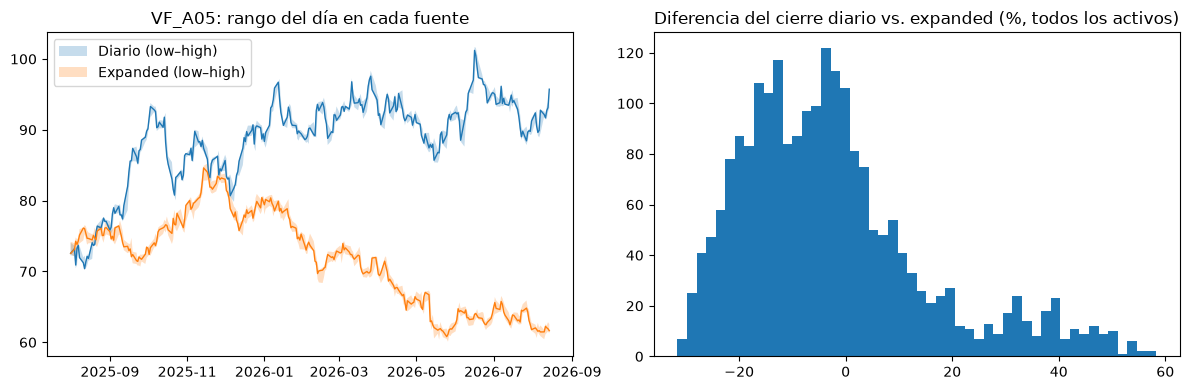

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
a = cmp[cmp.asset_id == 'VF_A05']
axes[0].fill_between(a.date, a.low_d, a.high_d, alpha=.25, label='Diario (low–high)')
axes[0].fill_between(a.date, a.low_e, a.high_e, alpha=.25, label='Expanded (low–high)')
axes[0].plot(a.date, a.close_d, lw=1); axes[0].plot(a.date, a.close_e, lw=1)
axes[0].set_title('VF_A05: rango del día en cada fuente'); axes[0].legend()
axes[1].hist(cmp.dif_close, bins=50)
axes[1].set_title('Diferencia del cierre diario vs. expanded (%, todos los activos)')
plt.tight_layout()

El error ×100 del archivo diario (VF_A06, 2026-03-23) es otra prueba de independencia: si una fuente saliera de la otra, el error aparecería en las dos.

In [17]:
cmp[(cmp.asset_id == 'VF_A06') & (cmp.date == '2026-03-23')][['date', 'asset_id', 'close_d', 'close_e']]

,date,asset_id,close_d,close_e
1521,2026-03-23,VF_A06,35.89,40.67


In [18]:
diverge = cmp[['dif_open', 'dif_high', 'dif_low', 'dif_close']].abs().ge(0.1).any(axis=1)
issues.append(('Entre archivos', 'Diario y expanded no coinciden en open, high, low, close ni volumen', int(diverge.sum()), 'Elegir una fuente; no mezclarlas'))
exp_daily = exp_ohlc[['asset_id', 'date', 'close']].rename(columns={'close': 'close_exp'})

**Conclusión:** no es un error en una columna. Son dos series de precios independientes que solo comparten el cierre del 1 de agosto de 2025, y cada una es coherente por dentro. En el notebook 02 se prueba cuál es la confiable contrastándolas con la macro y los eventos.

## 6. Resumen de problemas y exportación

In [19]:
quality = pd.DataFrame(issues, columns=['tabla', 'problema', 'filas', 'corrección'])
quality = quality[quality.filas > 0].reset_index(drop=True)
display(quality)
print('Problemas distintos:', len(quality))

,tabla,problema,filas,corrección
0,01_market_prices_raw,asset_id mal escrito,3,Mapear al ID oficial
1,01_market_prices_raw,Fecha en formato MM/DD/YYYY,4,Parsear con formato mixto
2,01_market_prices_raw,Filas duplicadas,7,Eliminar duplicados
3,01_market_prices_raw,Volumen como texto con K,3,Convertir a número x1000
4,01_market_prices_raw,currency vacía,4,Rellenar con USD
5,01_market_prices_raw,volume vacío,3,Dejar nulo
6,01_market_prices_raw,Cierre x100 (error de punto decimal),1,Dividir entre 100
7,01_market_prices_raw_expanded,asset_id mal escrito,16,Mapear al ID oficial
8,01_market_prices_raw_expanded,Fecha en formato MM/DD/YYYY HH:MM,38,Parsear con formato mixto
9,01_market_prices_raw_expanded,Filas duplicadas,12,Eliminar duplicados


Problemas distintos: 20


In [20]:
prices.to_csv(CLEAN / 'prices_daily.csv', index=False)
exp_daily.to_csv(CLEAN / 'prices_expanded_daily.csv', index=False)
exp_ohlc.to_csv(CLEAN / 'prices_expanded_ohlcv_daily.csv', index=False)
macro.to_csv(CLEAN / 'macro.csv', index=False)
fund.to_csv(CLEAN / 'fundamentals.csv', index=False)
ref.to_csv(CLEAN / 'asset_reference.csv', index=False)
clients.to_csv(CLEAN / 'client_profiles.csv', index=False)
events_c.to_csv(CLEAN / 'events.csv', index=False)
quality.to_csv(CLEAN / 'quality_issues.csv', index=False)
sorted(p.name for p in CLEAN.glob('*.csv'))

['asset_reference.csv',
 'client_profiles.csv',
 'events.csv',
 'fundamentals.csv',
 'macro.csv',
 'prices_daily.csv',
 'prices_expanded_daily.csv',
 'prices_expanded_ohlcv_daily.csv',
 'quality_issues.csv']

**Supuestos de limpieza a declarar en la presentación**
- El ingreso de ISS_06 en junio 2025 se toma como 2,845.7 (en el crudo dice "1,845.7").
- La fila `Q4-2024` de ISS_02 se reasigna a 2025-06-30.
- La caja faltante de ISS_07 se interpola entre trimestres vecinos.
- El expanded se resume a un cierre por día (última barra) solo para compararlo; no se mezcla con el diario.